In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/default_of_credit_card_clients.csv')

In [3]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [5]:
rename_dict = {
    'PAY_0': 'delay_1_month_ago',
    'PAY_2': 'delay_2_months_ago',
    'PAY_3': 'delay_3_months_ago',
    'PAY_4': 'delay_4_months_ago',
    'PAY_5': 'delay_5_months_ago',
    'PAY_6': 'delay_6_months_ago',
    'BILL_AMT1': 'bill_1_month_ago',
    'BILL_AMT2': 'bill_2_months_ago',
    'BILL_AMT3': 'bill_3_months_ago',
    'BILL_AMT4': 'bill_4_months_ago',
    'BILL_AMT5': 'bill_5_months_ago',
    'BILL_AMT6': 'bill_6_months_ago',
    'PAY_AMT1': 'paid_1_month_ago',
    'PAY_AMT2': 'paid_2_months_ago',
    'PAY_AMT3': 'paid_3_months_ago',
    'PAY_AMT4': 'paid_4_months_ago',
    'PAY_AMT5': 'paid_5_months_ago',
    'PAY_AMT6': 'paid_6_months_ago',
    'default payment next month': 'target_default'
}
df.rename(columns=rename_dict, inplace=True)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ID                  30000 non-null  int64
 1   LIMIT_BAL           30000 non-null  int64
 2   SEX                 30000 non-null  int64
 3   EDUCATION           30000 non-null  int64
 4   MARRIAGE            30000 non-null  int64
 5   AGE                 30000 non-null  int64
 6   delay_1_month_ago   30000 non-null  int64
 7   delay_2_months_ago  30000 non-null  int64
 8   delay_3_months_ago  30000 non-null  int64
 9   delay_4_months_ago  30000 non-null  int64
 10  delay_5_months_ago  30000 non-null  int64
 11  delay_6_months_ago  30000 non-null  int64
 12  bill_1_month_ago    30000 non-null  int64
 13  bill_2_months_ago   30000 non-null  int64
 14  bill_3_months_ago   30000 non-null  int64
 15  bill_4_months_ago   30000 non-null  int64
 16  bill_5_months_ago   30000 non-null  int6

In [7]:
df = df.drop('ID', axis=1)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   LIMIT_BAL           30000 non-null  int64
 1   SEX                 30000 non-null  int64
 2   EDUCATION           30000 non-null  int64
 3   MARRIAGE            30000 non-null  int64
 4   AGE                 30000 non-null  int64
 5   delay_1_month_ago   30000 non-null  int64
 6   delay_2_months_ago  30000 non-null  int64
 7   delay_3_months_ago  30000 non-null  int64
 8   delay_4_months_ago  30000 non-null  int64
 9   delay_5_months_ago  30000 non-null  int64
 10  delay_6_months_ago  30000 non-null  int64
 11  bill_1_month_ago    30000 non-null  int64
 12  bill_2_months_ago   30000 non-null  int64
 13  bill_3_months_ago   30000 non-null  int64
 14  bill_4_months_ago   30000 non-null  int64
 15  bill_5_months_ago   30000 non-null  int64
 16  bill_6_months_ago   30000 non-null  int6

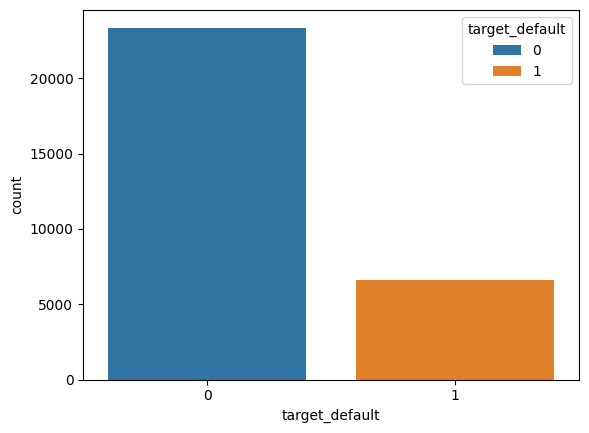

In [10]:
sns.countplot(data=df, x='target_default', hue='target_default');

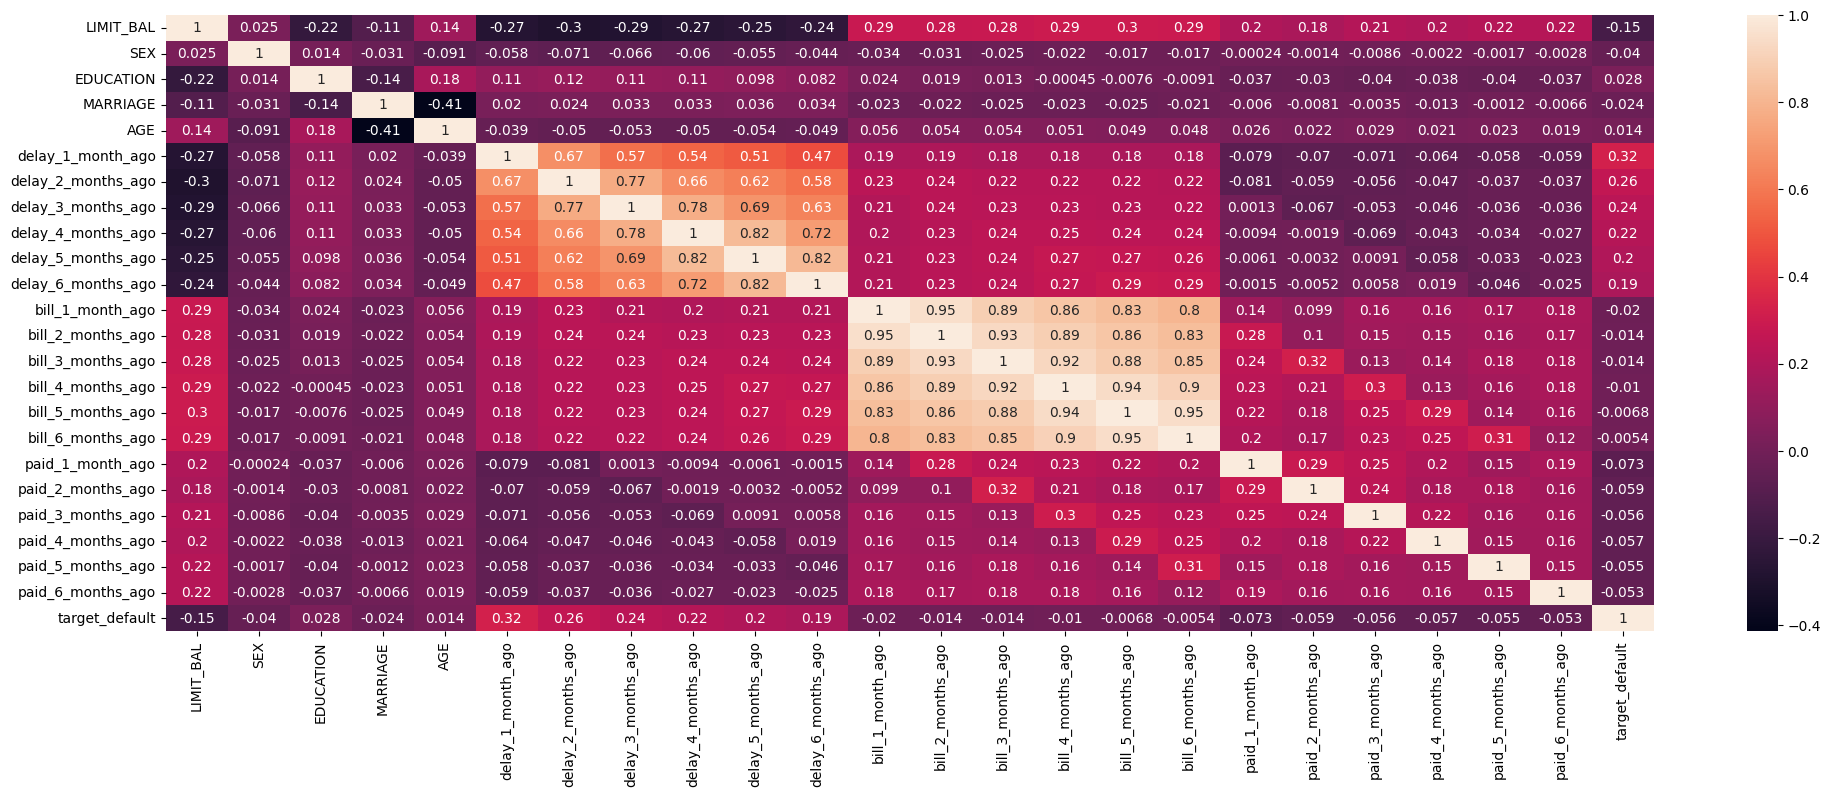

In [12]:
plt.figure(figsize=(24, 8))
sns.heatmap(df.corr(), annot=True);

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest

In [14]:
X = df.drop('target_default', axis=1)

In [15]:
y = df['target_default']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104)

In [17]:
iso_forest = IsolationForest(contamination=0.01, random_state=104, n_jobs=-1, n_estimators=100)

In [18]:
mask = iso_forest.fit_predict(X_train)

In [19]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [20]:
X_train_cleaned.shape

(23760, 23)

In [21]:
X_train.shape

(24000, 23)

In [28]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler())
])

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, X_train_cleaned.columns.tolist())
    ],
    remainder='passthrough'
)

In [63]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=7,
                                   cv=7,
                                  penalty='l2',
                                  solver='lbfgs',
                                  max_iter=1_00,
                                  n_jobs=-1,
                                  random_state=104,
                                   class_weight='balanced'))
])

In [64]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [65]:
%%time
pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 812 ms
Wall time: 8.7 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains 

In [66]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [67]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [0.0001]


In [68]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [69]:
accuracy

0.7906666666666666

In [70]:
recall

0.5563063063063063

In [71]:
precision

0.527027027027027

In [72]:
roc_auc_test

0.7667584840624686

In [73]:
roc_auc_train

0.7605628291934265

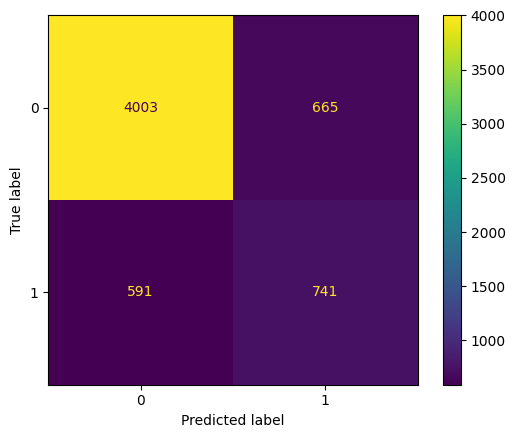

In [74]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

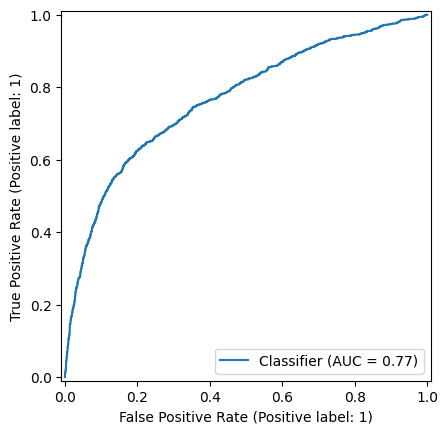

In [75]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [76]:
%%time
pipe.fit(X, y)

CPU times: total: 1.31 s
Wall time: 12.3 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains 

In [77]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")

Лучшее значение C: [0.0001]


In [78]:
y_full_proba = pipe.predict_proba(X)[:, 1]

In [79]:
roc_auc_full = roc_auc_score(y, y_full_proba)

In [80]:
roc_auc_full

0.7607937479276784

In [81]:
custom_credit_df = pd.DataFrame([
    {
        'LIMIT_BAL': 20000, 'SEX': 2, 'EDUCATION': 2, 'MARRIAGE': 2, 'AGE': 22,
        'delay_1_month_ago': 2, 'delay_2_months_ago': 2, 'delay_3_months_ago': 2,
        'delay_4_months_ago': 2, 'delay_5_months_ago': 2, 'delay_6_months_ago': 2,
        'bill_1_month_ago': 19000, 'bill_2_months_ago': 18500, 'bill_3_months_ago': 18000,
        'bill_4_months_ago': 17500, 'bill_5_months_ago': 17000, 'bill_6_months_ago': 16500,
        'paid_1_month_ago': 0, 'paid_2_months_ago': 0, 'paid_3_months_ago': 0,
        'paid_4_months_ago': 0, 'paid_5_months_ago': 0, 'paid_6_months_ago': 0
    },
    {
        'LIMIT_BAL': 500000, 'SEX': 1, 'EDUCATION': 1, 'MARRIAGE': 1, 'AGE': 40,
        'delay_1_month_ago': -1, 'delay_2_months_ago': -1, 'delay_3_months_ago': -1,
        'delay_4_months_ago': -1, 'delay_5_months_ago': -1, 'delay_6_months_ago': -1,
        'bill_1_month_ago': 5000, 'bill_2_months_ago': 3000, 'bill_3_months_ago': 8000,
        'bill_4_months_ago': 4000, 'bill_5_months_ago': 2000, 'bill_6_months_ago': 6000,
        'paid_1_month_ago': 5000, 'paid_2_months_ago': 3000, 'paid_3_months_ago': 8000,
        'paid_4_months_ago': 4000, 'paid_5_months_ago': 2000, 'paid_6_months_ago': 6000
    }
])

In [82]:
custom_credit_df

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,delay_1_month_ago,delay_2_months_ago,delay_3_months_ago,delay_4_months_ago,delay_5_months_ago,...,bill_3_months_ago,bill_4_months_ago,bill_5_months_ago,bill_6_months_ago,paid_1_month_ago,paid_2_months_ago,paid_3_months_ago,paid_4_months_ago,paid_5_months_ago,paid_6_months_ago
0,20000,2,2,2,22,2,2,2,2,2,...,18000,17500,17000,16500,0,0,0,0,0,0
1,500000,1,1,1,40,-1,-1,-1,-1,-1,...,8000,4000,2000,6000,5000,3000,8000,4000,2000,6000


In [83]:
preds = pipe.predict(custom_credit_df)
preds_proba = pipe.predict_proba(custom_credit_df)

In [84]:
classes_map = {
    0: "СТАБИЛЬНЫЙ КЛИЕНТ (выплаты без задержек) 🟢",
    1: "РИСК ДЕФОЛТА (высокая вероятность невозврата) 🚨"
}

expected_list = [
    "МОЛОДОЙ СТУДЕНТ С МИНИМАЛЬНЫМ ЛИМИТОМ И ХРОНИЧЕСКИМИ ПРОСРОЧКАМИ",
    "ОПЫТНЫЙ ТОП-МЕНЕДЖЕР С ВЫСОКИМ КРЕДИТНЫМ ЛИМИТОМ И ЧИСТОЙ ИСТОРИЕЙ"
]

print("=" * 90)
print("🏦  ДЕПЛОЙ СЛУЖБЫ АВТОМАТИЧЕСКОГО КРЕДИТНОГО СКОРИНГА И ОЦЕНКИ РИСКОВ БАНКА")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n👤 АНКЕТА ЗАЕМЩИКА №{idx + 1}:")
    print(f" -> Профиль анкеты:     {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:  {classes_map[class_out]}")
    print(f" -> Уверенность логита: {prob:.2f}%  📊")
    print("-" * 90)

🏦  ДЕПЛОЙ СЛУЖБЫ АВТОМАТИЧЕСКОГО КРЕДИТНОГО СКОРИНГА И ОЦЕНКИ РИСКОВ БАНКА

👤 АНКЕТА ЗАЕМЩИКА №1:
 -> Профиль анкеты:     МОЛОДОЙ СТУДЕНТ С МИНИМАЛЬНЫМ ЛИМИТОМ И ХРОНИЧЕСКИМИ ПРОСРОЧКАМИ
 -> Вердикт ИИ-модели:  РИСК ДЕФОЛТА (высокая вероятность невозврата) 🚨
 -> Уверенность логита: 83.32%  📊
------------------------------------------------------------------------------------------

👤 АНКЕТА ЗАЕМЩИКА №2:
 -> Профиль анкеты:     ОПЫТНЫЙ ТОП-МЕНЕДЖЕР С ВЫСОКИМ КРЕДИТНЫМ ЛИМИТОМ И ЧИСТОЙ ИСТОРИЕЙ
 -> Вердикт ИИ-модели:  СТАБИЛЬНЫЙ КЛИЕНТ (выплаты без задержек) 🟢
 -> Уверенность логита: 63.90%  📊
------------------------------------------------------------------------------------------


In [85]:
class_percents = df['target_default'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 77.9%, 1: 22.1%


In [86]:
import json
import os

advanced_report = {
    "project": "Credit Card Default Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-08',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [87]:
from joblib import dump, load
import os

In [88]:
os.makedirs('model', exist_ok=True)

In [89]:
dump(pipe, "model/credit_card_default_predict_logistic_regression_cv_2026_v1.pkl")

['model/credit_card_default_predict_logistic_regression_cv_2026_v1.pkl']

In [90]:
loaded_pipe = load("model/credit_card_default_predict_logistic_regression_cv_2026_v1.pkl")

In [91]:
preds = loaded_pipe.predict(custom_credit_df)
preds_proba = loaded_pipe.predict_proba(custom_credit_df)

In [92]:
classes_map = {
    0: "СТАБИЛЬНЫЙ КЛИЕНТ (выплаты без задержек) 🟢",
    1: "РИСК ДЕФОЛТА (высокая вероятность невозврата) 🚨"
}

expected_list = [
    "МОЛОДОЙ СТУДЕНТ С МИНИМАЛЬНЫМ ЛИМИТОМ И ХРОНИЧЕСКИМИ ПРОСРОЧКАМИ",
    "ОПЫТНЫЙ ТОП-МЕНЕДЖЕР С ВЫСОКИМ КРЕДИТНЫМ ЛИМИТОМ И ЧИСТОЙ ИСТОРИЕЙ"
]

print("=" * 90)
print("🏦  ДЕПЛОЙ СЛУЖБЫ АВТОМАТИЧЕСКОГО КРЕДИТНОГО СКОРИНГА И ОЦЕНКИ РИСКОВ БАНКА")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n👤 АНКЕТА ЗАЕМЩИКА №{idx + 1}:")
    print(f" -> Профиль анкеты:     {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:  {classes_map[class_out]}")
    print(f" -> Уверенность логита: {prob:.2f}%  📊")
    print("-" * 90)

🏦  ДЕПЛОЙ СЛУЖБЫ АВТОМАТИЧЕСКОГО КРЕДИТНОГО СКОРИНГА И ОЦЕНКИ РИСКОВ БАНКА

👤 АНКЕТА ЗАЕМЩИКА №1:
 -> Профиль анкеты:     МОЛОДОЙ СТУДЕНТ С МИНИМАЛЬНЫМ ЛИМИТОМ И ХРОНИЧЕСКИМИ ПРОСРОЧКАМИ
 -> Вердикт ИИ-модели:  РИСК ДЕФОЛТА (высокая вероятность невозврата) 🚨
 -> Уверенность логита: 83.32%  📊
------------------------------------------------------------------------------------------

👤 АНКЕТА ЗАЕМЩИКА №2:
 -> Профиль анкеты:     ОПЫТНЫЙ ТОП-МЕНЕДЖЕР С ВЫСОКИМ КРЕДИТНЫМ ЛИМИТОМ И ЧИСТОЙ ИСТОРИЕЙ
 -> Вердикт ИИ-модели:  СТАБИЛЬНЫЙ КЛИЕНТ (выплаты без задержек) 🟢
 -> Уверенность логита: 63.90%  📊
------------------------------------------------------------------------------------------
